In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv('/content/drive/MyDrive/Ames_Housing_Data.csv')

In [4]:
df

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,AllPub,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


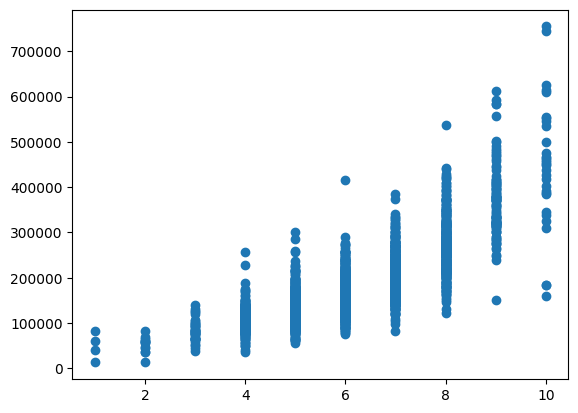

In [ ]:
plt.scatter(df['Overall Qual'],df['SalePrice'])

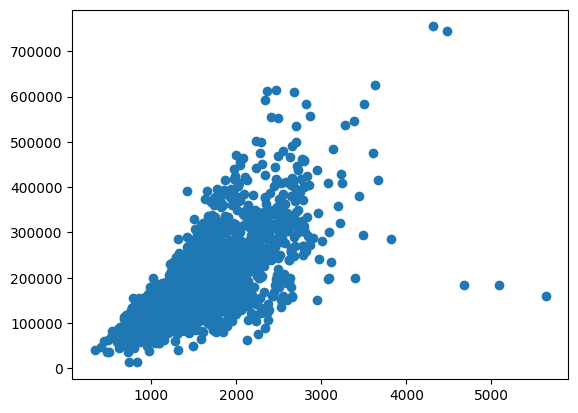

In [ ]:
plt.scatter(df['Gr Liv Area'],df['SalePrice'])

Outlayers'lerin silinmesi

In [ ]:
df[(df['Overall Qual']>8) & (df['SalePrice']<200000)][['Overall Qual','SalePrice','Gr Liv Area']]

,Overall Qual,SalePrice,Gr Liv Area
1182,9,150000,2944
1498,10,160000,5642
2180,10,183850,5095
2181,10,184750,4676


In [ ]:
df[(df['Gr Liv Area']>4000) & (df['SalePrice']<200000)][['Overall Qual','SalePrice','Gr Liv Area']]
# Bu 3 sutun overall qual sutundada outliersdi

,Overall Qual,SalePrice,Gr Liv Area
1498,10,160000,5642
2180,10,183850,5095
2181,10,184750,4676


In [ ]:
drop_ind=df[(df['Gr Liv Area']>4000) & (df['SalePrice']<200000)].index
drop_ind

Index([1498, 2180, 2181], dtype='int64')

In [ ]:
df=df.drop(drop_ind,axis=0)

In [ ]:
df=df.drop('PID',axis=1)

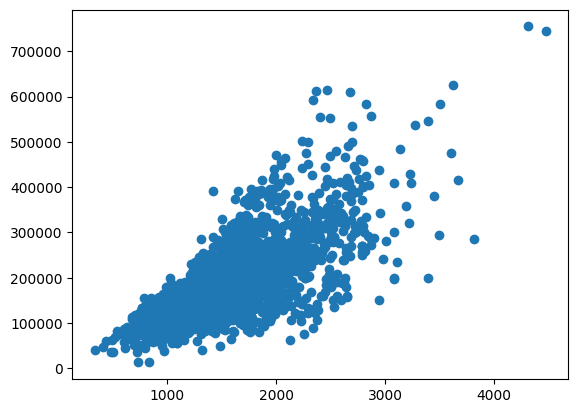

In [ ]:
plt.scatter(df['Gr Liv Area'],df['SalePrice'])

In [ ]:
corrs=df.corr(numeric_only=1)['SalePrice'].sort_values()

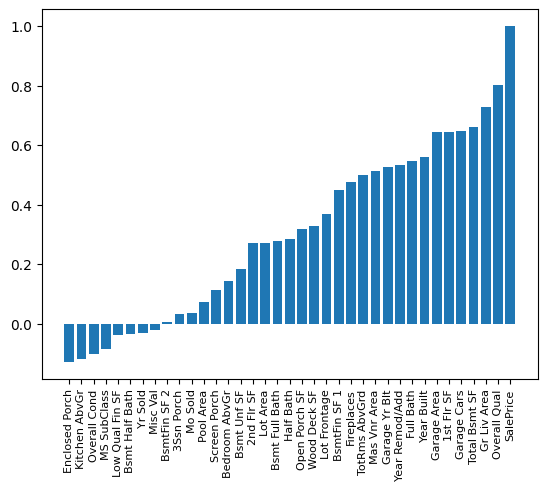

In [ ]:
plt.bar(x=corrs.index,height=corrs.values)
plt.xticks(rotation='vertical',size=8)
plt.show()

In [ ]:
def percent_nas(frame):
  sr=frame.isna().sum().sort_values()/len(df)*100
  return sr[sr>0]

In [ ]:
nas=percent_nas(df)
nas

,0
Garage Area,0.034165
Electrical,0.034165
Garage Cars,0.034165
Total Bsmt SF,0.034165
Bsmt Unf SF,0.034165
BsmtFin SF 1,0.034165
BsmtFin SF 2,0.034165
Bsmt Full Bath,0.068329
Bsmt Half Bath,0.068329
Mas Vnr Area,0.785787


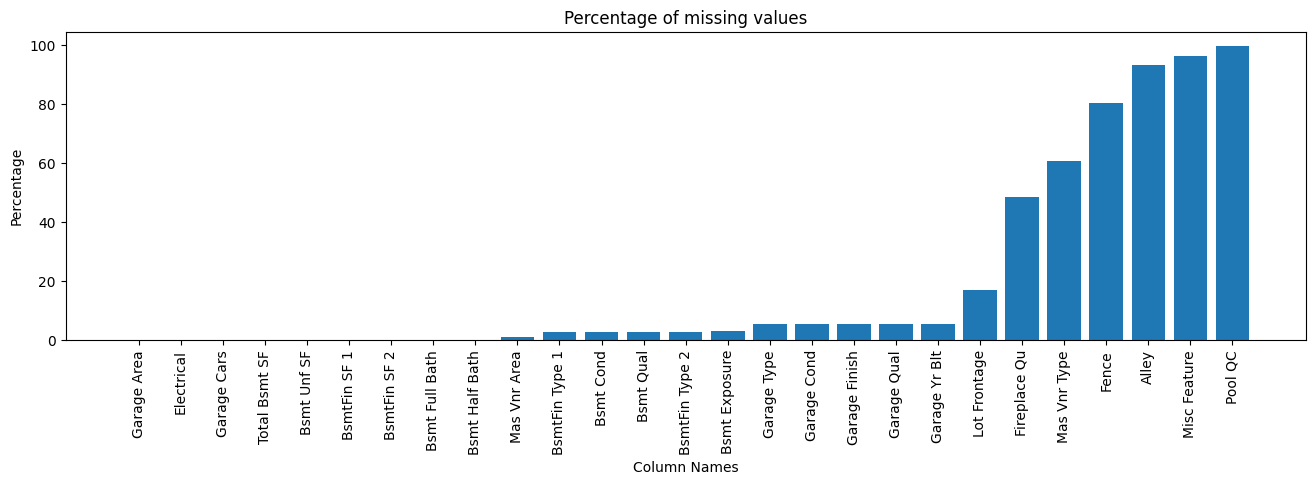

In [ ]:
plt.figure(figsize=(16,4))
plt.bar(x=nas.index,height=nas.values)
plt.title('Percentage of missing values')
plt.xlabel('Column Names')
plt.ylabel('Percentage')
plt.xticks(rotation='vertical')
plt.show()

# Silinecek setirler

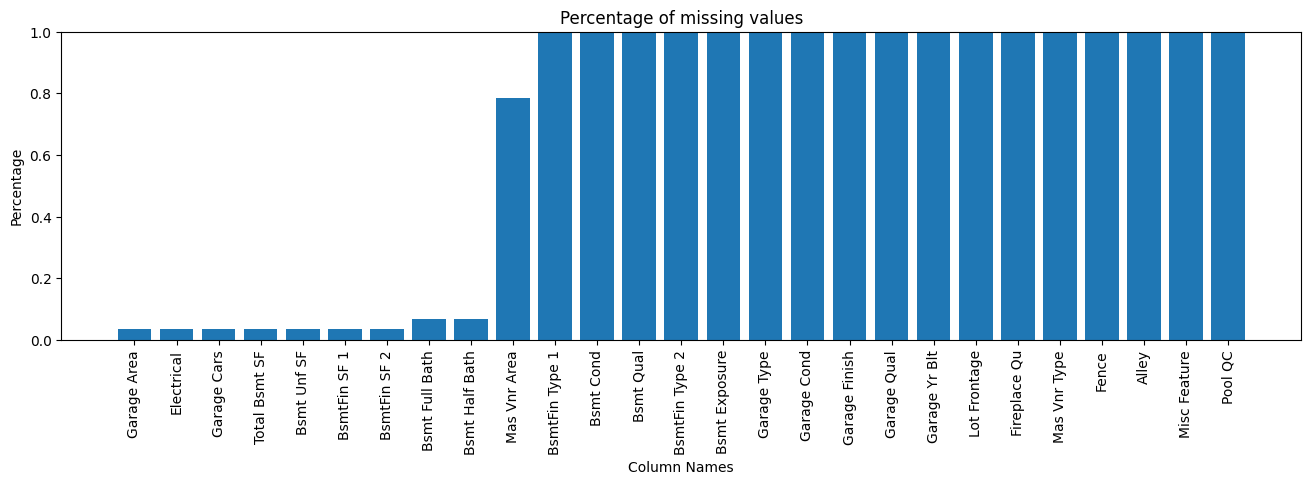

In [ ]:
plt.figure(figsize=(16,4))
plt.bar(x=nas.index,height=nas.values)
plt.title('Percentage of missing values')
plt.xlabel('Column Names')
plt.ylabel('Percentage')
plt.xticks(rotation='vertical')
plt.ylim((0,1))
plt.show()

In [ ]:
nas[nas<1]

,0
Garage Area,0.034165
Electrical,0.034165
Garage Cars,0.034165
Total Bsmt SF,0.034165
Bsmt Unf SF,0.034165
BsmtFin SF 1,0.034165
BsmtFin SF 2,0.034165
Bsmt Full Bath,0.068329
Bsmt Half Bath,0.068329
Mas Vnr Area,0.785787


In [ ]:
100/len(df) #1 setirin faiz ceheti

0.0341646737273659

Electrical	0.034165
Garage Cars	0.034165
Total Bsmt SF	0.034165
Bsmt Unf SF	0.034165
BsmtFin SF 1	0.034165
BsmtFin SF 2	0.034165
her birinde 1 eded 1 Na setiri var

In [ ]:
df[df['Electrical'].isnull()]

,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
1577,80,RL,73.0,9735,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,167500


In [ ]:
df=df.dropna(axis=0,subset=['Electrical','Garage Cars'])

In [ ]:
nas_after_editing=percent_nas(df)
nas_after_editing

,0
Total Bsmt SF,0.034188
Bsmt Unf SF,0.034188
BsmtFin SF 2,0.034188
BsmtFin SF 1,0.034188
Bsmt Full Bath,0.068376
Bsmt Half Bath,0.068376
Mas Vnr Area,0.786325
BsmtFin Type 1,2.735043
Bsmt Cond,2.735043
Bsmt Qual,2.735043


In [ ]:
nas_after_editing[(nas_after_editing>0) & (nas_after_editing<1)]

,0
Total Bsmt SF,0.034188
Bsmt Unf SF,0.034188
BsmtFin SF 2,0.034188
BsmtFin SF 1,0.034188
Bsmt Full Bath,0.068376
Bsmt Half Bath,0.068376
Mas Vnr Area,0.786325


In [ ]:
with open('/content/drive/MyDrive/Ames_Housing_Feature_Description.txt','r') as f:
  for text in f:
    print(text)

MSSubClass: Identifies the type of dwelling involved in the sale.	



        20	1-STORY 1946 & NEWER ALL STYLES

        30	1-STORY 1945 & OLDER

        40	1-STORY W/FINISHED ATTIC ALL AGES

        45	1-1/2 STORY - UNFINISHED ALL AGES

        50	1-1/2 STORY FINISHED ALL AGES

        60	2-STORY 1946 & NEWER

        70	2-STORY 1945 & OLDER

        75	2-1/2 STORY ALL AGES

        80	SPLIT OR MULTI-LEVEL

        85	SPLIT FOYER

        90	DUPLEX - ALL STYLES AND AGES

       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER

       150	1-1/2 STORY PUD - ALL AGES

       160	2-STORY PUD - 1946 & NEWER

       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER

       190	2 FAMILY CONVERSION - ALL STYLES AND AGES



MSZoning: Identifies the general zoning classification of the sale.

		

       A	Agriculture

       C	Commercial

       FV	Floating Village Residential

       I	Industrial

       RH	Residential High Density

       RL	Residential Low Density

       RP	Residential 

In [ ]:
bsmt_num_cols = ['BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF','Total Bsmt SF', 'Bsmt Full Bath', 'Bsmt Half Bath']
df[bsmt_num_cols] = df[bsmt_num_cols].fillna(0)

In [ ]:
bsmt_str_cols =  ['Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2']
df[bsmt_str_cols] = df[bsmt_str_cols].fillna('None')

In [ ]:
nas=percent_nas(df)
nas

,0
Mas Vnr Area,0.786325
Garage Type,5.367521
Garage Cond,5.401709
Garage Finish,5.401709
Garage Qual,5.401709
Garage Yr Blt,5.401709
Lot Frontage,16.752137
Fireplace Qu,48.547009
Mas Vnr Type,60.615385
Fence,80.478632


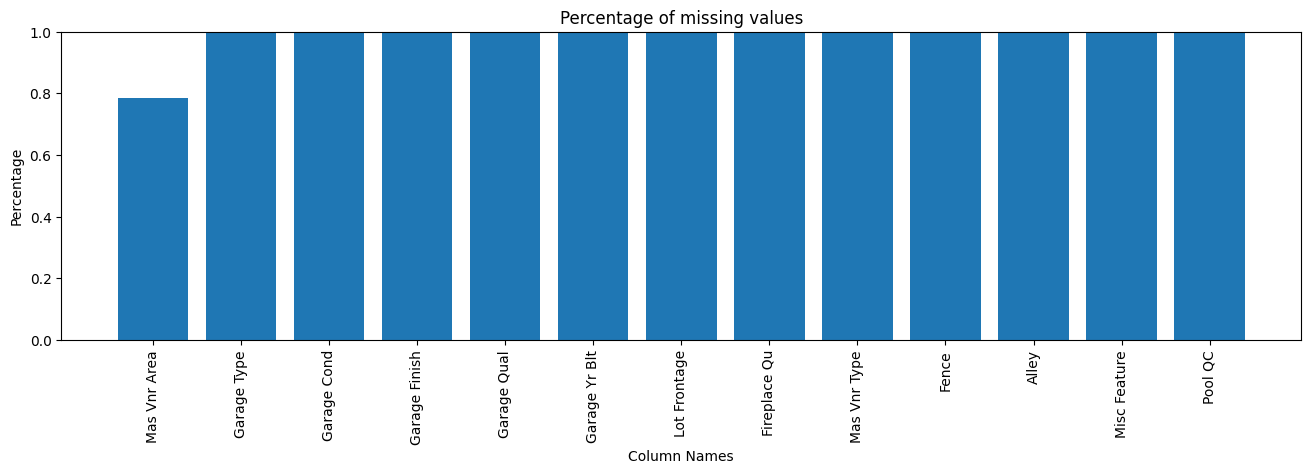

In [ ]:
plt.figure(figsize=(16,4))
plt.bar(x=nas.index,height=nas.values)
plt.title('Percentage of missing values')
plt.xlabel('Column Names')
plt.ylabel('Percentage')
plt.xticks(rotation='vertical')
plt.ylim((0,1))
plt.show()

In [ ]:
df['Mas Vnr Area']=df['Mas Vnr Area'].fillna(0)


In [ ]:
df['Mas Vnr Type']=df['Mas Vnr Type'].fillna('None')

In [ ]:
nas=percent_nas(df)
nas

,0
Garage Type,5.367521
Garage Finish,5.401709
Garage Qual,5.401709
Garage Yr Blt,5.401709
Garage Cond,5.401709
Lot Frontage,16.752137
Fireplace Qu,48.547009
Fence,80.478632
Alley,93.230769
Misc Feature,96.410256


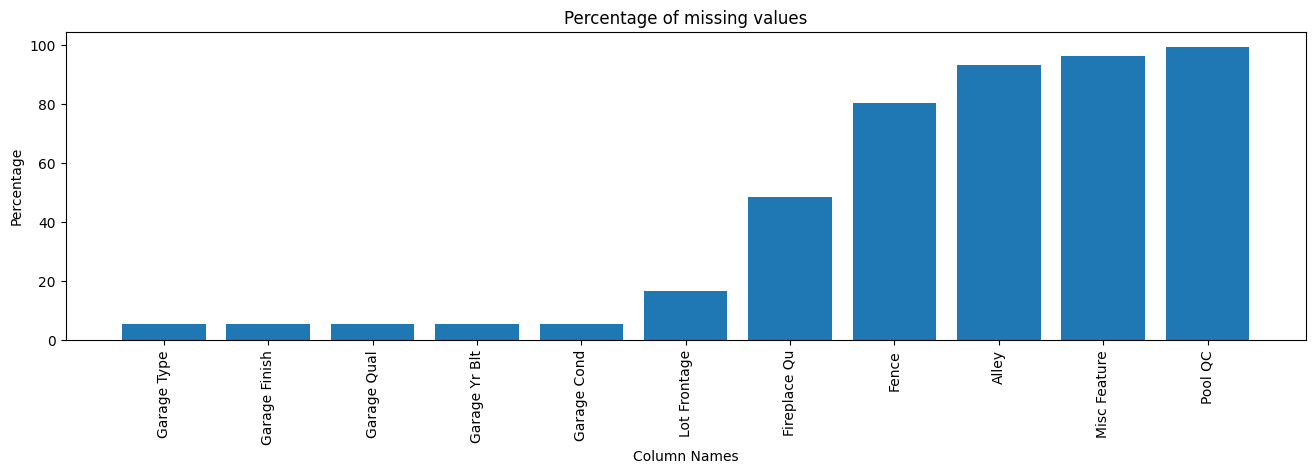

In [ ]:
plt.figure(figsize=(16,4))
plt.bar(x=nas.index,height=nas.values)
plt.title('Percentage of missing values')
plt.xlabel('Column Names')
plt.ylabel('Percentage')
plt.xticks(rotation='vertical')
plt.show()

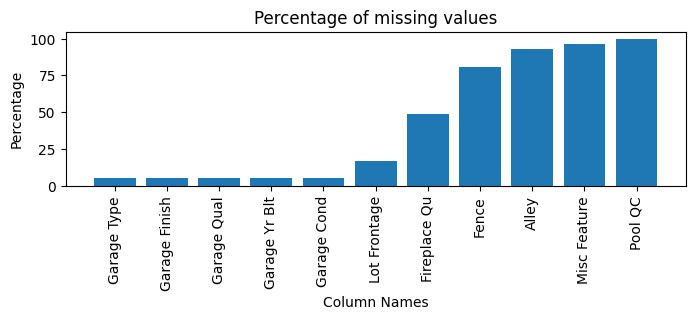

In [ ]:
plt.figure(figsize=(8,2))
plt.bar(x=nas.index,height=nas.values)
plt.title('Percentage of missing values')
plt.xlabel('Column Names')
plt.ylabel('Percentage')
plt.xticks(rotation='vertical')
# plt.ylim((0,1))
plt.show()

In [ ]:
df[['Garage Type','Garage Finish','Garage Qual','Garage Cond']]=df[['Garage Type','Garage Finish','Garage Qual','Garage Cond']].fillna('None')

In [ ]:
df['Garage Yr Blt']=df['Garage Yr Blt'].fillna(0)

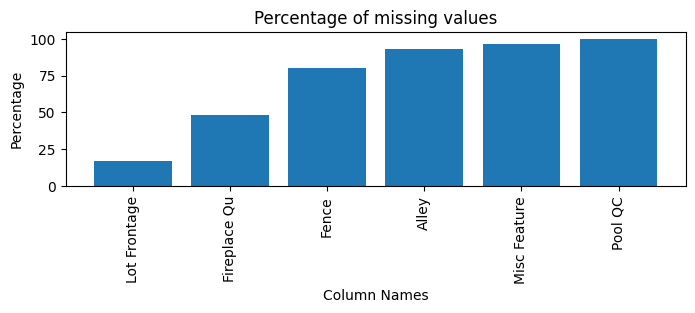

In [ ]:
nas=percent_nas(df)
plt.figure(figsize=(8,2))
plt.bar(x=nas.index,height=nas.values)
plt.title('Percentage of missing values')
plt.xlabel('Column Names')
plt.ylabel('Percentage')
plt.xticks(rotation='vertical')
# plt.ylim((0,1))
plt.show()

In [ ]:
nas

,0
Lot Frontage,16.752137
Fireplace Qu,48.547009
Fence,80.478632
Alley,93.230769
Misc Feature,96.410256
Pool QC,99.589744


In [ ]:
df=df.drop(['Fence','Alley','Misc Feature','Pool QC'],axis=1)

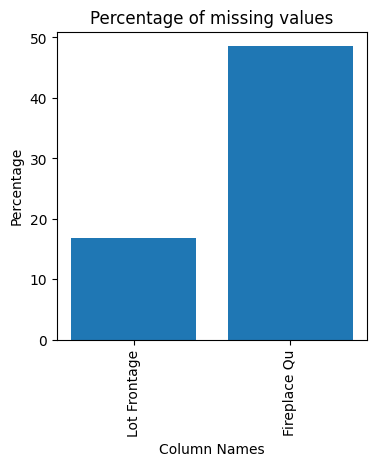

In [ ]:
nas=percent_nas(df)
plt.figure(figsize=(4,4))
plt.bar(x=nas.index,height=nas.values)
plt.title('Percentage of missing values')
plt.xlabel('Column Names')
plt.ylabel('Percentage')
plt.xticks(rotation='vertical')
# plt.ylim((0,1))
plt.show()

In [ ]:
df.groupby('Neighborhood')['Lot Frontage'].mean()

,Lot Frontage
Neighborhood,
Blmngtn,46.900000
Blueste,27.300000
BrDale,21.500000
BrkSide,55.789474
ClearCr,88.150000
CollgCr,71.336364
Crawfor,69.951807
Edwards,64.794286
Gilbert,74.207207


In [ ]:
df['Lot Frontage']=df.groupby('Neighborhood')['Lot Frontage'].transform(lambda x: x.fillna(x.mean()))

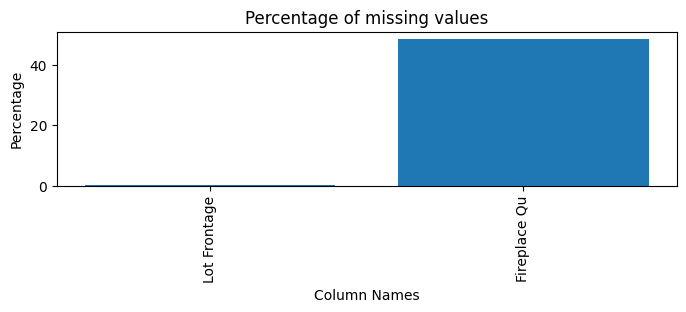

In [ ]:
nas=percent_nas(df)
plt.figure(figsize=(8,2))
plt.bar(x=nas.index,height=nas.values)
plt.title('Percentage of missing values')
plt.xlabel('Column Names')
plt.ylabel('Percentage')
plt.xticks(rotation='vertical')
# plt.ylim((0,1))
plt.show()

In [ ]:
df['Lot Frontage']=df['Lot Frontage'].fillna(0)

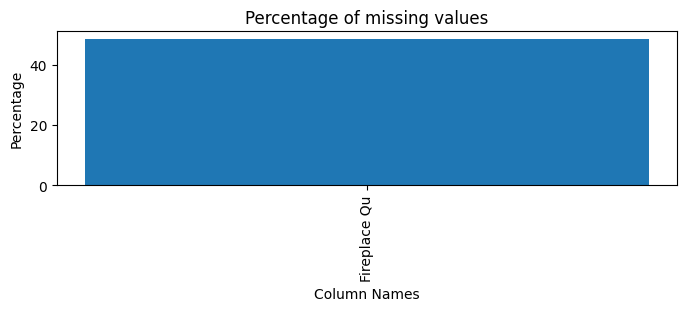

In [ ]:
nas=percent_nas(df)
plt.figure(figsize=(8,2))
plt.bar(x=nas.index,height=nas.values)
plt.title('Percentage of missing values')
plt.xlabel('Column Names')
plt.ylabel('Percentage')
plt.xticks(rotation='vertical')
# plt.ylim((0,1))
plt.show()

In [ ]:
df['Fireplace Qu']=df['Fireplace Qu'].fillna('None')


In [ ]:
nas=percent_nas(df)
nas

,0


In [ ]:
df['MS SubClass']=df['MS SubClass'].transform(str)

# ML Modelini guraq

In [ ]:
X=df.drop('SalePrice',axis=1)
y=df['SalePrice']

In [ ]:
num_cols = X.select_dtypes(exclude="object").columns
cat_cols = X.select_dtypes(include="object").columns

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore",min_frequency=15), cat_cols)
])

In [ ]:
X_train=preprocessor.fit_transform(X_train)
X_test=preprocessor.transform(X_test)

In [ ]:
from sklearn.linear_model import Lasso

In [ ]:
lasso_model=Lasso(max_iter=30000,alpha=0.001)

In [ ]:
lasso_model.fit(X_train,y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 256889081342.2618, tolerance: 1453164171.5372057
  model = cd_fast.sparse_enet_coordinate_descent(


Lasso(alpha=0.001, max_iter=30000)

In [ ]:
from sklearn.metrics import mean_absolute_error,root_mean_squared_error

In [ ]:
y_pred=lasso_model.predict(X_test)

In [ ]:
mean_absolute_error(y_test,y_pred)

14347.425534138385

In [ ]:
y_test.mean()

np.float64(183145.82905982906)

In [ ]:
lasso_model.score(X_test,y_test)

0.932671465304545

In [ ]:
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV

svr_model=SVR()

params=[{'kernel':['linear', 'rbf'],
        'gamma' : ['scale', 'auto'],
        'C':[1,1000,10000,30000],
        'epsilon':[0,0.1,1]
        },
        {'kernel':['poly'],
         'gamma' : ['scale', 'auto'],
         'C':[1,1000,10000,30000],
         'degree':[2,3],
        'epsilon':[0,0.1,1]
         }]
grid=GridSearchCV(estimator=svr_model,param_grid=params,verbose=2)

In [ ]:
grid.fit(X_train,y_train)

Fitting 5 folds for each of 96 candidates, totalling 480 fits
[CV] END .........C=1, epsilon=0, gamma=scale, kernel=linear; total time=   1.4s
[CV] END .........C=1, epsilon=0, gamma=scale, kernel=linear; total time=   1.3s
[CV] END .........C=1, epsilon=0, gamma=scale, kernel=linear; total time=   1.3s
[CV] END .........C=1, epsilon=0, gamma=scale, kernel=linear; total time=   1.7s
[CV] END .........C=1, epsilon=0, gamma=scale, kernel=linear; total time=   1.9s
[CV] END ............C=1, epsilon=0, gamma=scale, kernel=rbf; total time=   1.9s
[CV] END ............C=1, epsilon=0, gamma=scale, kernel=rbf; total time=   1.4s
[CV] END ............C=1, epsilon=0, gamma=scale, kernel=rbf; total time=   1.4s
[CV] END ............C=1, epsilon=0, gamma=scale, kernel=rbf; total time=   1.4s
[CV] END ............C=1, epsilon=0, gamma=scale, kernel=rbf; total time=   1.4s
[CV] END ..........C=1, epsilon=0, gamma=auto, kernel=linear; total time=   1.3s
[CV] END ..........C=1, epsilon=0, gamma=auto, 

GridSearchCV(estimator=SVR(),
             param_grid=[{'C': [1, 1000, 10000, 30000], 'epsilon': [0, 0.1, 1],
                          'gamma': ['scale', 'auto'],
                          'kernel': ['linear', 'rbf']},
                         {'C': [1, 1000, 10000, 30000], 'degree': [2, 3],
                          'epsilon': [0, 0.1, 1], 'gamma': ['scale', 'auto'],
                          'kernel': ['poly']}],
             verbose=2)

In [ ]:
grid.best_estimator_.get_params()

{'C': 30000,
 'cache_size': 200,
 'coef0': 0.0,
 'degree': 2,
 'epsilon': 1,
 'gamma': 'scale',
 'kernel': 'poly',
 'max_iter': -1,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

'C': 30000,
 'cache_size': 200,
 'coef0': 0.0,
 'degree': 2,
 'epsilon': 1,
 'gamma': 'scale',
 'kernel': 'poly',
 'max_iter': -1,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

In [ ]:
grid.score(X_test,y_test)

0.9562124852956451

In [ ]:
y_pred=grid.predict(X_test)

In [ ]:
mae=mean_absolute_error(y_test,y_pred)
rmse=root_mean_squared_error(y_test,y_pred)

In [ ]:
mae,rmse

(11585.521188070621, 17636.13526697818)